# Ridership Analysis: Free Fare Routes vs. Route 28

This notebook compares Boston's fare-free bus routes (**23, 28 and 29**) with **Route 22**, which serves the same neighborhoods but still charges a fare.

- Route 28 became fare-free in **August 2021**
- Routes 23 and 29 became fare-free in **March 2022**

All data comes from the cleaned files in `data/processed`.

## 0. Setup

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

processed = r'C:\Users\sahil\projects\boston-mbta-ridership\data\processed'
figures   = r'C:\Users\sahil\projects\boston-mbta-ridership\figures'


colors = {'23': '#F6A96B', '28': '#E87A90', '29': '#B39CD0', '22': '#7FB3D5'}

route_year = pd.read_csv(processed + r'\ridership_route_year.csv', dtype={'route_id': str})
weekday = route_year[route_year['day_type'] == 'weekday']

## Ridership: Focus Routes

### 1. Weekday riders, 2016–2025

Average weekday boardings on each route, Fall 2016 to Fall 2025.
The grey band marks 2020 (COVID), and the dotted lines mark when each route became fare-free.

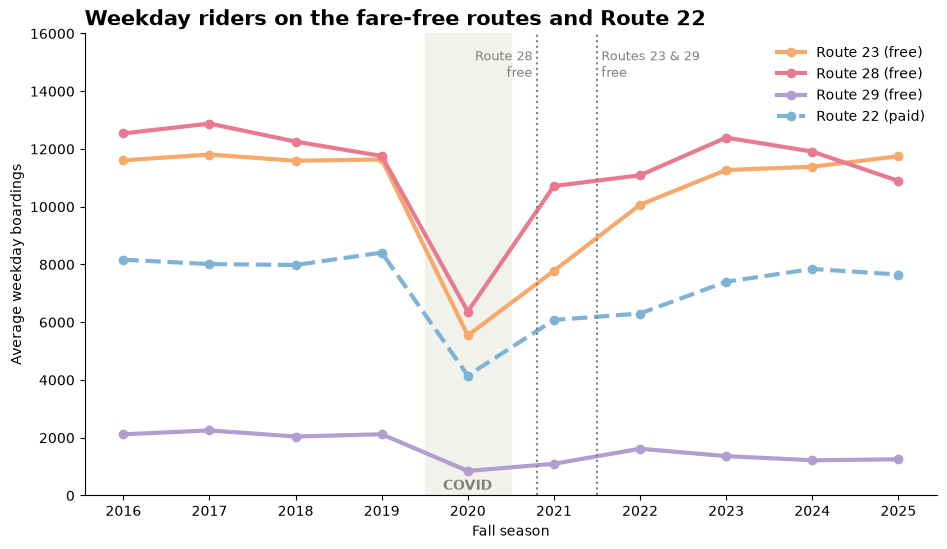

In [3]:
fig, ax = plt.subplots(figsize=(11, 6))

r23 = weekday[weekday['route_id'] == '23'].sort_values('year')
r28 = weekday[weekday['route_id'] == '28'].sort_values('year')
r29 = weekday[weekday['route_id'] == '29'].sort_values('year')
r22 = weekday[weekday['route_id'] == '22'].sort_values('year')


ax.plot(r23['year'], r23['avg_daily_boardings'], color=colors['23'], linewidth=3, marker='o', label='Route 23 (free)')
ax.plot(r28['year'], r28['avg_daily_boardings'], color=colors['28'], linewidth=3, marker='o', label='Route 28 (free)')
ax.plot(r29['year'], r29['avg_daily_boardings'], color=colors['29'], linewidth=3, marker='o', label='Route 29 (free)')
ax.plot(r22['year'], r22['avg_daily_boardings'], color=colors['22'], linewidth=3, marker='o', linestyle='--', label='Route 22 (paid)')

ax.axvspan(2019.5, 2020.5, color='#F2F2EC')
ax.text(2020, 200, 'COVID', ha='center', fontsize=10, color='gray', fontweight='bold')

# Fare-free start dates
ax.axvline(2020.8, color='gray', linestyle=':')
ax.axvline(2021.5, color='gray', linestyle=':')
ax.text(2020.75, 14500, 'Route 28\nfree', ha='right', fontsize=9, color='gray')
ax.text(2021.55, 14500, 'Routes 23 & 29\nfree', fontsize=9, color='gray')


ax.set_title('Weekday riders on the fare-free routes and Route 22', fontsize=15, fontweight='bold', loc='left')
ax.set_xlabel('Fall season')
ax.set_ylabel('Average weekday boardings')
ax.set_xticks(range(2016, 2026))
ax.set_ylim(0, 16000)
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)

plt.savefig(figures + r'\Weekday Riders on the Free-Fare Routes and Route 22.png', dpi=300, bbox_inches='tight')
plt.show()

**Takeaway:** All four routes collapsed in 2020. Route 28 rebounded sharply in its first fare-free fall (2021), and Route 23 climbed back to its pre-COVID level after becoming free in 2022. Route 22, which kept its fare, is still below its 2019 ridership. Route 29 stayed low, reflecting service cuts rather than the fare change.

### 2. Did ridership follow service?

Left: change in **service** (weekday trips), January–February 2020 to January–February 2025.
Right: change in **riders** (weekday boardings), Fall 2019 to Fall 2025.

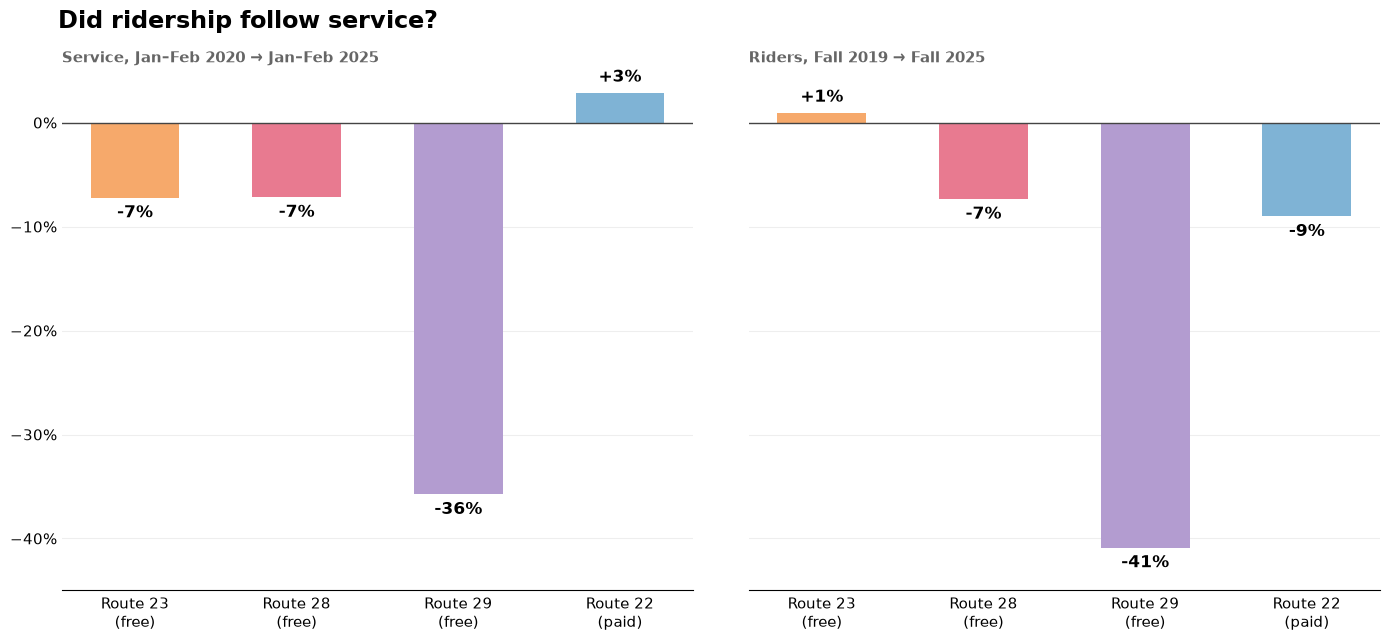

In [4]:
import matplotlib.ticker as mticker

service = pd.read_csv(processed + r'\service_route_month.csv', dtype={'route_id': str})
winter = service[(service['day_type'] == 'weekday') & (service['month'].isin([1, 2]))]

trips_2020 = winter[winter['year'] == 2020].groupby('route_id')['n_trips'].sum()
trips_2025 = winter[winter['year'] == 2025].groupby('route_id')['n_trips'].sum()
trip_change = (trips_2025/trips_2020 - 1)*100

riders = weekday.pivot(index='year', columns='route_id', values='avg_daily_boardings')
rider_change = (riders.loc[2025]/riders.loc[2019] - 1)*100


routes = ['23', '28', '29', '22']
names  = ['Route 23\n(free)', 'Route 28\n(free)', 'Route 29\n(free)', 'Route 22\n(paid)']
bar_colors = [colors['23'], colors['28'], colors['29'], colors['22']]

service_values = trip_change[routes]
rider_values   = rider_change[routes]



fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)

#Left
bars1 = ax1.bar(names, service_values, color=bar_colors, width=0.55)
ax1.bar_label(bars1, labels=[f'{v:+.0f}%' for v in service_values], padding=5, fontsize=12, fontweight='bold')
ax1.set_title('Service, Jan–Feb 2020 → Jan–Feb 2025', fontsize=11, fontweight='bold', color='#666666', loc='left')

#Right
bars2 = ax2.bar(names, rider_values, color=bar_colors, width=0.55)
ax2.bar_label(bars2, labels=[f'{v:+.0f}%' for v in rider_values], padding=5, fontsize=12, fontweight='bold')
ax2.set_title('Riders, Fall 2019 → Fall 2025', fontsize=11, fontweight='bold', color='#666666', loc='left')


ax1.set_ylim(-45, 5)                                         
ax1.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))

ax1.axhline(0, color='#444444', linewidth=1)
ax2.axhline(0, color='#444444', linewidth=1)

ax1.grid(axis='y', color='#EEEEEE')
ax2.grid(axis='y', color='#EEEEEE')
ax1.set_axisbelow(True)
ax2.set_axisbelow(True)

ax1.spines[['top', 'right', 'left']].set_visible(False)
ax2.spines[['top', 'right', 'left']].set_visible(False)
ax1.tick_params(length=0, labelsize=11)
ax2.tick_params(length=0, labelsize=11)

fig.suptitle('Did ridership follow service?', fontsize=17, fontweight='bold', x=0.045, ha='left')

plt.tight_layout(w_pad=4)
plt.savefig(figures + r'\RidershipvsService.png', dpi=300, bbox_inches='tight')
plt.show()

**Takeaway:** Route 22, which kept its fare, gained 2.9% more service but still lost 9.0% of its riders. Route 23 lost 7.2% of its service yet gained riders (+1.0%), and Route 28 lost riders (−7.4%) only in line with its service cut (−7.2%). Route 29's ridership fell (−40.9%) almost exactly as far as its service (−35.8%), so free fares could not offset deep service cuts.

### 3. Fare-free routes vs. Route 22, before and after adjusting for service

Ridership change alone is affected by **service changes** - Route 22 gained service (+2.9%) while the fare-free routes lost it, so the raw comparison understates their advantage.

The adjusted comparison measures ridership **relative to service** (riders per trip run):

$$\text{Adjusted change} = \left(\frac{1 + \text{riders change}/100}{1 + \text{service change}/100} - 1\right) \times 100$$

Riders: Fall 2019 → Fall 2025 · Service: January–February 2020 → January–February 2025

In [5]:
routes = ['23', '28', '29', '22']

riders_pct  = rider_change[routes]        
service_pct = trip_change[routes]           


per_trip_pct = ((1 + riders_pct / 100) / (1 + service_pct / 100) - 1) * 100

did = pd.DataFrame({
    'Riders change (%)': riders_pct,
    'Service change (%)': service_pct,
    'vs. Route 22, raw (pts)': riders_pct - riders_pct['22'],
    'vs. Route 22, adjusted (pts)': per_trip_pct - per_trip_pct['22'],
})
did.index = ['Route 23 (free)', 'Route 28 (free)', 'Route 29 (free)', 'Route 22 (paid)']

did.style.format('{:+.1f}')

,Riders change (%),Service change (%),"vs. Route 22, raw (pts)","vs. Route 22, adjusted (pts)"
Route 23 (free),+1.0,-7.2,+10.0,+20.4
Route 28 (free),-7.4,-7.2,+1.7,+11.4
Route 29 (free),-40.9,-35.8,-31.9,+3.6
Route 22 (paid),-9.0,+2.9,+0.0,+0.0


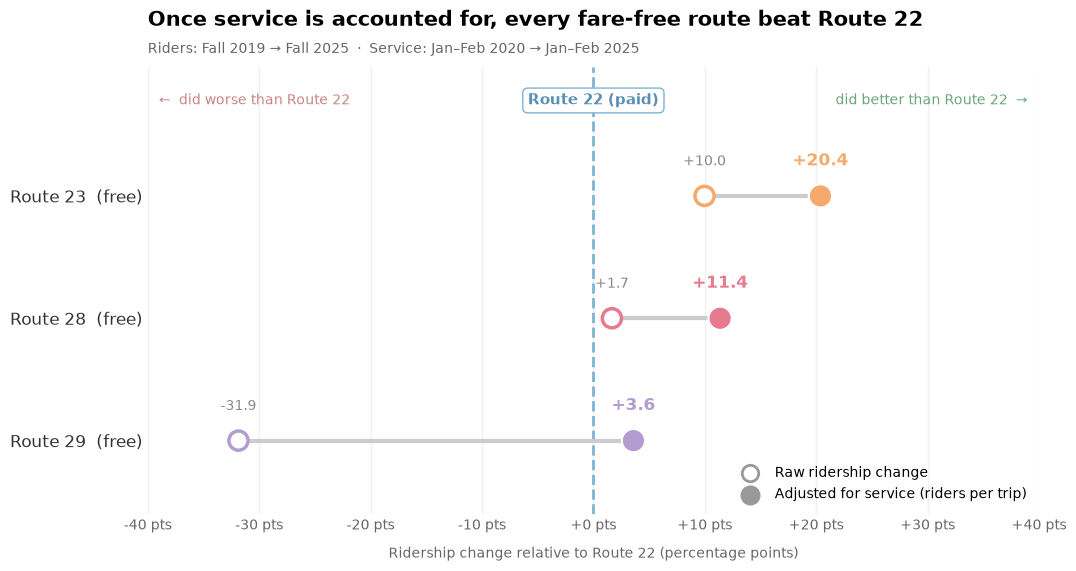

In [6]:
import matplotlib.ticker as mticker


raw = riders_pct - riders_pct['22']
adj = per_trip_pct - per_trip_pct['22']

fig, ax = plt.subplots(figsize=(11.5, 5.8))

ax.grid(axis='x', color='#F0F0F0', linewidth=1)
ax.set_axisbelow(True)


ax.axvline(0, color=colors['22'], linewidth=2, linestyle='--', zorder=1)
ax.text(0, 2.78, 'Route 22 (paid)', ha='center', va='center', fontsize=10.5, fontweight='bold', color='#5A8FB3',
        bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor=colors['22']))
ax.text(-39, 2.78, '←  did worse than Route 22', ha='left', va='center', fontsize=10, color='#C98585')
ax.text(39, 2.78, 'did better than Route 22  →', ha='right', va='center', fontsize=10, color='#6AA67A')

ax.hlines([2, 1, 0], [raw['23'], raw['28'], raw['29']], [adj['23'], adj['28'], adj['29']],
          color='#CCCCCC', linewidth=3, zorder=2)


ax.scatter([raw['23'], raw['28'], raw['29']], [2, 1, 0], s=190, facecolor='white',
           edgecolor=[colors['23'], colors['28'], colors['29']], linewidth=2.5, zorder=3)
ax.scatter([adj['23'], adj['28'], adj['29']], [2, 1, 0], s=280,
           color=[colors['23'], colors['28'], colors['29']], edgecolor='white', linewidth=1.5, zorder=4)


ax.text(raw['23'], 2.25, f"{raw['23']:+.1f}", ha='center', fontsize=10, color='#888888')
ax.text(adj['23'], 2.25, f"{adj['23']:+.1f}", ha='center', fontsize=12.5, fontweight='bold', color=colors['23'])
ax.text(raw['28'], 1.25, f"{raw['28']:+.1f}", ha='center', fontsize=10, color='#888888')
ax.text(adj['28'], 1.25, f"{adj['28']:+.1f}", ha='center', fontsize=12.5, fontweight='bold', color=colors['28'])
ax.text(raw['29'], 0.25, f"{raw['29']:+.1f}", ha='center', fontsize=10, color='#888888')
ax.text(adj['29'], 0.25, f"{adj['29']:+.1f}", ha='center', fontsize=12.5, fontweight='bold', color=colors['29'])


ax.scatter([], [], s=140, facecolor='white', edgecolor='#999999', linewidth=2, label='Raw ridership change')
ax.scatter([], [], s=180, color='#999999', label='Adjusted for service (riders per trip)')
ax.legend(loc='lower right', frameon=False, fontsize=10)


ax.set_yticks([2, 1, 0])
ax.set_yticklabels(['Route 23  (free)', 'Route 28  (free)', 'Route 29  (free)'], fontsize=12)
ax.set_xlim(-40, 40)
ax.set_ylim(-0.6, 3.05)
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%+d pts'))
ax.set_xlabel('Ridership change relative to Route 22 (percentage points)', color='#666666', labelpad=10)
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(length=0, colors='#666666')
ax.tick_params(axis='y', colors='#333333')

ax.set_title('Once service is accounted for, every fare-free route beat Route 22',
             fontsize=15, fontweight='bold', loc='left', pad=30)
fig.text(0.125, 0.905, 'Riders: Fall 2019 → Fall 2025  ·  Service: Jan–Feb 2020 → Jan–Feb 2025',
         fontsize=10, color='#666666')

plt.savefig(figures + r'\ServiceAdjustedRoute22.png', dpi=300, bbox_inches='tight')
plt.show()

**Takeaway:** On raw numbers, Routes 23 and 28 did better than Route 22 (+10.0 and +1.7 points) and Route 29 did much worse (−31.9). But Route 22 gained service while the fare-free routes lost it. Once ridership is measured relative to service, all three fare-free routes outperformed Route 22: Route 23 by 20.4 points, Route 28 by 11.4 and Route 29 by 3.6. Route 29's large raw loss came from service cuts, not the fare change.

*Caveat:* the adjustment assumes riders change one-for-one with service. In practice ridership usually falls less than service, so the adjusted gaps are an upper estimate; the true effect lies between the raw and adjusted values.

## Ridership: All Routes

How did the fare-free routes compare with the rest of the MBTA bus network?
Comparison groups:
- **Top 8 routes:** the 8 busiest other routes in 2019 (1, 66, 39, 57, 111, 32, 22, 9)
- **All other routes:** every remaining bus route
Silver Line routes are excluded (bus rapid transit, with different ridership drivers).

### 1. Fare-free routes' share of all weekday bus riders

Routes 23, 28 and 29 as a percentage of all weekday MBTA bus riders (Silver Line excluded).
A rising share means these routes grew faster, or shrank more slowly, than the network as a whole.

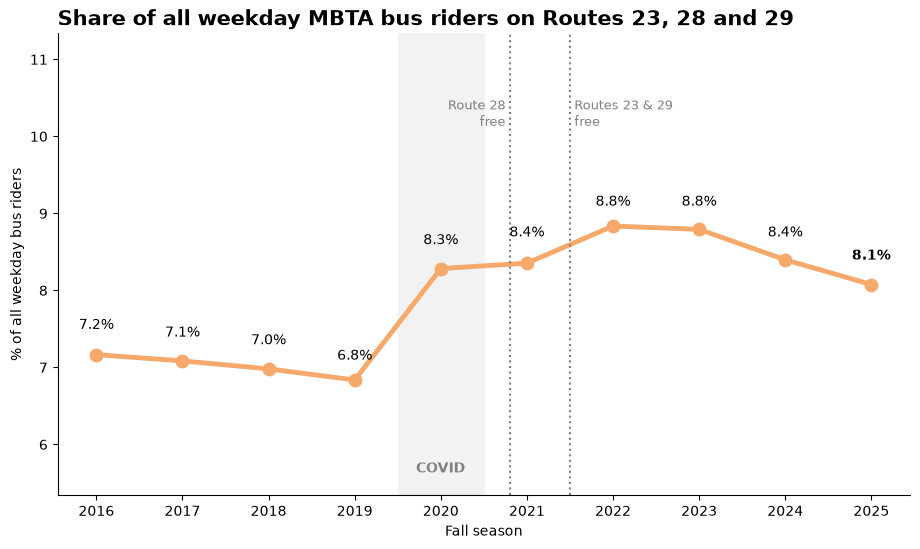

In [7]:

fare_free   = ['23', '28', '29']
top8        = ['1', '66', '39', '57', '111', '32', '22', '9']
silver_line = ['741', '742', '743', '746', '749', '751']

network = weekday[weekday['route_id'].isin(silver_line) == False]


free_total = network[network['route_id'].isin(fare_free)].groupby('year')['avg_daily_boardings'].sum()
top8_total = network[network['route_id'].isin(top8)].groupby('year')['avg_daily_boardings'].sum()
rest_total = network[(network['route_id'].isin(fare_free) == False) &
                     (network['route_id'].isin(top8) == False)].groupby('year')['avg_daily_boardings'].sum()


all_total = network.groupby('year')['avg_daily_boardings'].sum()
share = free_total / all_total * 100

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(share.index, share, color='#F6A96B', linewidth=3.5, marker='o', markersize=9)


for_label = share.round(1)
ax.text(2016, for_label[2016] + 0.3, f'{for_label[2016]}%', ha='center', fontsize=10)
ax.text(2017, for_label[2017] + 0.3, f'{for_label[2017]}%', ha='center', fontsize=10)
ax.text(2018, for_label[2018] + 0.3, f'{for_label[2018]}%', ha='center', fontsize=10)
ax.text(2019, for_label[2019] + 0.3, f'{for_label[2019]}%', ha='center', fontsize=10)
ax.text(2020, for_label[2020] + 0.3, f'{for_label[2020]}%', ha='center', fontsize=10)
ax.text(2021, for_label[2021] + 0.3, f'{for_label[2021]}%', ha='center', fontsize=10)
ax.text(2022, for_label[2022] + 0.3, f'{for_label[2022]}%', ha='center', fontsize=10)
ax.text(2023, for_label[2023] + 0.3, f'{for_label[2023]}%', ha='center', fontsize=10)
ax.text(2024, for_label[2024] + 0.3, f'{for_label[2024]}%', ha='center', fontsize=10)
ax.text(2025, for_label[2025] + 0.3, f'{for_label[2025]}%', ha='center', fontsize=10, fontweight='bold')


ax.axvspan(2019.5, 2020.5, color='#F2F2F2')
ax.text(2020, share.min() - 1.2, 'COVID', ha='center', fontsize=10, color='gray', fontweight='bold')
ax.axvline(2020.8, color='gray', linestyle=':')
ax.axvline(2021.5, color='gray', linestyle=':')
ax.text(2020.75, share.max() + 1.3, 'Route 28\nfree', ha='right', fontsize=9, color='gray')
ax.text(2021.55, share.max() + 1.3, 'Routes 23 & 29\nfree', fontsize=9, color='gray')

ax.set_title('Share of all weekday MBTA bus riders on Routes 23, 28 and 29', fontsize=15, fontweight='bold', loc='left')
ax.set_xlabel('Fall season')
ax.set_ylabel('% of all weekday bus riders')
ax.set_xticks(range(2016, 2026))
ax.set_ylim(share.min() - 1.5, share.max() + 2.5)
ax.spines[['top', 'right']].set_visible(False)

plt.savefig(figures + r'\Shareofallbusriders.png', dpi=300, bbox_inches='tight')
plt.show()

**Takeaway:** The fare-free routes carried 6.8% of all weekday bus riders in 2019 and 8.8% in 2022–2023, before easing to 8.1% in 2025.

*Caveat:* much of the jump happened in 2020 (6.8% → 8.3%), before fares were removed: riders on these routes depend on transit and kept riding through COVID more than riders elsewhere. The rise after 2021 (8.4% → 8.8%) is the part more plausibly linked to free fares.

### 2. Does the result depend on which routes we compare against?

Route 22 is a single route, so we check the result against two larger groups as well: the **8 busiest other routes** and **all other routes**.
Routes 23, 28 and 29 are combined into one fare-free group (total riders and total trips).

**Step 1: Change in riders** for each group, Fall 2019 to Fall 2025:

$$R = \left(\frac{\text{riders}_{2025}}{\text{riders}_{2019}} - 1\right) \times 100$$

**Step 2: Change in service** (weekday trips), January–February 2020 to January–February 2025:

$$S = \left(\frac{\text{trips}_{2025}}{\text{trips}_{2020}} - 1\right) \times 100$$

**Step 3: Change in riders per trip**, i.e. ridership adjusted for service:

$$A = \left(\frac{1 + R/100}{1 + S/100} - 1\right) \times 100$$

For example, if riders fell 7% and service fell 7%, riders per trip did not change (A = 0).

**Step 4: Gap between the fare-free routes and each comparison group:**

$$\text{Raw gap} = R_{\text{fare-free}} - R_{\text{group}} \qquad \text{Adjusted gap} = A_{\text{fare-free}} - A_{\text{group}}$$

A positive gap means the fare-free routes did better than that group. The **hollow dot** is the raw gap; the **filled dot** is the adjusted gap.
If both dots are positive against every group, the result does not depend on choosing Route 22 as the comparison.

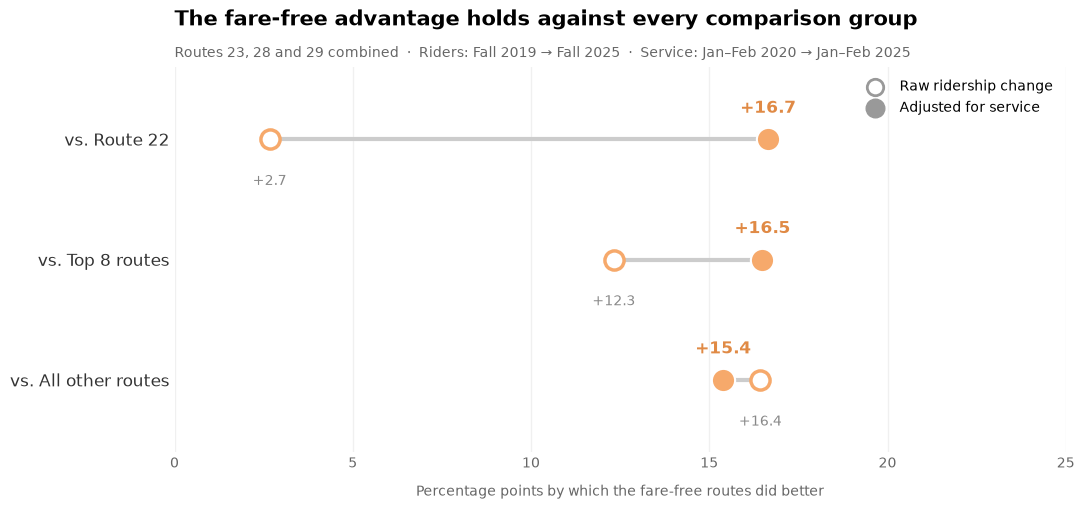

In [8]:
other_routes = network[(network['route_id'].isin(fare_free) == False) &
                       (network['route_id'].isin(top8) == False)]['route_id'].unique()

# %change in riders
riders_free = (free_total[2025] / free_total[2019] - 1) * 100
riders_22   = (riders.loc[2025, '22'] / riders.loc[2019, '22'] - 1) * 100
riders_top8 = (top8_total[2025] / top8_total[2019] - 1) * 100
riders_rest = (rest_total[2025] / rest_total[2019] - 1) * 100

# %change in service
service_free = (trips_2025.reindex(fare_free).sum() / trips_2020.reindex(fare_free).sum() - 1) * 100
service_22   = (trips_2025['22'] / trips_2020['22'] - 1) * 100
service_top8 = (trips_2025.reindex(top8).sum() / trips_2020.reindex(top8).sum() - 1) * 100
service_rest = (trips_2025.reindex(other_routes).sum() / trips_2020.reindex(other_routes).sum() - 1) * 100

# Riders per trip (adjusted for service)
adj_free = ((1 + riders_free / 100) / (1 + service_free / 100) - 1) * 100
adj_22   = ((1 + riders_22 / 100)   / (1 + service_22 / 100) - 1) * 100
adj_top8 = ((1 + riders_top8 / 100) / (1 + service_top8 / 100) - 1) * 100
adj_rest = ((1 + riders_rest / 100) / (1 + service_rest / 100) - 1) * 100

# Gap: fare-free minus each comparison group
raw_vals = [riders_free - riders_22, riders_free - riders_top8, riders_free - riders_rest]
adj_vals = [adj_free - adj_22,       adj_free - adj_top8,       adj_free - adj_rest]
fig, ax = plt.subplots(figsize=(11.5, 5))

ax.grid(axis='x', color='#F0F0F0', linewidth=1)
ax.set_axisbelow(True)


ax.hlines([2, 1, 0], raw_vals, adj_vals, color='#CCCCCC', linewidth=3, zorder=2)
ax.scatter(raw_vals, [2, 1, 0], s=190, facecolor='white', edgecolor='#F6A96B', linewidth=2.5, zorder=3)
ax.scatter(adj_vals, [2, 1, 0], s=280, color='#F6A96B', edgecolor='white', linewidth=1.5, zorder=4)


ax.text(raw_vals[0], 1.62, f'{raw_vals[0]:+.1f}', ha='center', fontsize=10, color='#888888')
ax.text(adj_vals[0], 2.22, f'{adj_vals[0]:+.1f}', ha='center', fontsize=12.5, fontweight='bold', color='#E08A45')
ax.text(raw_vals[1], 0.62, f'{raw_vals[1]:+.1f}', ha='center', fontsize=10, color='#888888')
ax.text(adj_vals[1], 1.22, f'{adj_vals[1]:+.1f}', ha='center', fontsize=12.5, fontweight='bold', color='#E08A45')
ax.text(raw_vals[2], -0.38, f'{raw_vals[2]:+.1f}', ha='center', fontsize=10, color='#888888')
ax.text(adj_vals[2], 0.22, f'{adj_vals[2]:+.1f}', ha='center', fontsize=12.5, fontweight='bold', color='#E08A45')


ax.scatter([], [], s=140, facecolor='white', edgecolor='#999999', linewidth=2, label='Raw ridership change')
ax.scatter([], [], s=180, color='#999999', label='Adjusted for service')
ax.legend(loc='upper right', frameon=False, fontsize=10)

ax.set_yticks([2, 1, 0])
ax.set_yticklabels(['vs. Route 22', 'vs. Top 8 routes', 'vs. All other routes'], fontsize=12)
ax.set_xlim(0, 25)
ax.set_ylim(-0.6, 2.6)
ax.set_xlabel('Percentage points by which the fare-free routes did better', color='#666666', labelpad=10)
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(length=0, colors='#666666')
ax.tick_params(axis='y', colors='#333333')

ax.set_title('The fare-free advantage holds against every comparison group',
             fontsize=15, fontweight='bold', loc='left', pad=30)
fig.text(0.125, 0.90, 'Routes 23, 28 and 29 combined  ·  Riders: Fall 2019 → Fall 2025  ·  Service: Jan–Feb 2020 → Jan–Feb 2025',
         fontsize=10, color='#666666')


plt.savefig(figures + r'\Advantageagainsteachgroup.png', dpi=300, bbox_inches='tight')
plt.show()

**Takeaway:** The fare-free routes outperformed every comparison group, by 2.7 to 16.4 points on raw ridership and by 15.4 to 16.7 points after adjusting for service. The adjusted gaps are remarkably consistent, whether the comparison is Route 22, the 8 busiest routes or the whole network, so the result does not depend on the choice of comparison route.

### 3. Riders beyond each route's share of service

For each route: its share of all weekday bus riders minus its share of all weekday trips run, each Fall (Silver Line excluded).

$$\text{Gap} = \text{share of riders} - \text{share of trips}$$

Above 0 means the route carries more riders than its share of buses would suggest. A gap that grows after the routes became fare-free means they attracted riders faster than their service grew.

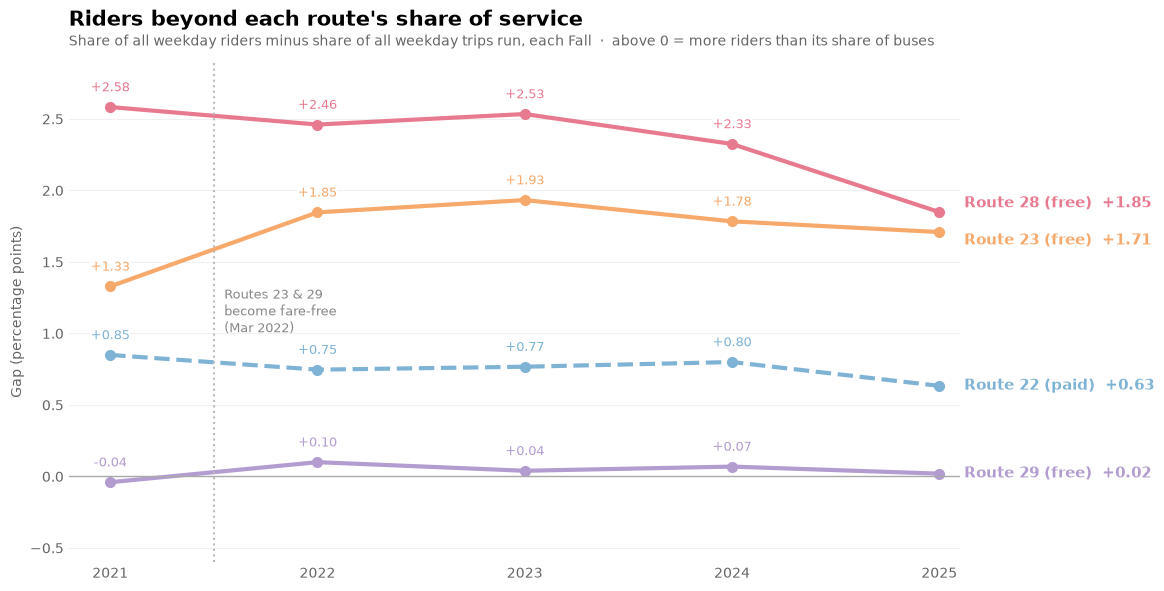

In [9]:

network_routes = network['route_id'].unique()
fall_all = service[(service['day_type'] == 'weekday') & (service['month'].between(9, 12)) &
                   (service['route_id'].isin(network_routes))]

trips_all  = fall_all.groupby('year')['n_trips'].sum()
riders_all = network.groupby('year')['avg_daily_boardings'].sum()

trips_by_route = fall_all.pivot_table(index='year', columns='route_id', values='n_trips', aggfunc='sum')
rider_share = (riders.div(riders_all, axis=0) * 100).loc[2021:2025]
trip_share  = (trips_by_route.div(trips_all, axis=0) * 100).loc[2021:2025]

gap = rider_share - trip_share

fig, ax = plt.subplots(figsize=(11.5, 6.5))

ax.plot(gap.index, gap['28'], color=colors['28'], linewidth=3, marker='o', markersize=7)
ax.plot(gap.index, gap['23'], color=colors['23'], linewidth=3, marker='o', markersize=7)
ax.plot(gap.index, gap['22'], color=colors['22'], linewidth=3, marker='o', markersize=7, linestyle='--')
ax.plot(gap.index, gap['29'], color=colors['29'], linewidth=3, marker='o', markersize=7)

box = dict(facecolor='white', edgecolor='none', pad=0.5)
[ax.text(x, y + 0.11, f'{y:+.2f}', ha='center', fontsize=9, color=colors['28'], bbox=box) for x, y in gap.loc[2021:2024, '28'].items()]
[ax.text(x, y + 0.11, f'{y:+.2f}', ha='center', fontsize=9, color=colors['23'], bbox=box) for x, y in gap.loc[2021:2024, '23'].items()]
[ax.text(x, y + 0.11, f'{y:+.2f}', ha='center', fontsize=9, color=colors['22'], bbox=box) for x, y in gap.loc[2021:2024, '22'].items()]
[ax.text(x, y + 0.11, f'{y:+.2f}', ha='center', fontsize=9, color=colors['29'], bbox=box) for x, y in gap.loc[2021:2024, '29'].items()]

ax.text(2025.12, gap.loc[2025, '28'] + 0.06, f"Route 28 (free)  {gap.loc[2025, '28']:+.2f}", va='center', fontsize=10.5, fontweight='bold', color=colors['28'])
ax.text(2025.12, gap.loc[2025, '23'] - 0.06, f"Route 23 (free)  {gap.loc[2025, '23']:+.2f}", va='center', fontsize=10.5, fontweight='bold', color=colors['23'])
ax.text(2025.12, gap.loc[2025, '22'],        f"Route 22 (paid)  {gap.loc[2025, '22']:+.2f}", va='center', fontsize=10.5, fontweight='bold', color=colors['22'])
ax.text(2025.12, gap.loc[2025, '29'],        f"Route 29 (free)  {gap.loc[2025, '29']:+.2f}", va='center', fontsize=10.5, fontweight='bold', color=colors['29'])

ax.axhline(0, color='#AAAAAA', linewidth=1)

ax.axvline(2021.5, color='#BBBBBB', linestyle=':', linewidth=1.5)
ax.text(2021.55, 1.15, 'Routes 23 & 29\nbecome fare-free\n(Mar 2022)', fontsize=9.5, color='#888888', va='center')

ax.set_title("Riders beyond each route's share of service", fontsize=15, fontweight='bold', loc='left', pad=26)
fig.text(0.125, 0.905, 'Share of all weekday riders minus share of all weekday trips run, each Fall  ·  above 0 = more riders than its share of buses',
         fontsize=10, color='#666666')
ax.set_ylabel('Gap (percentage points)', color='#666666')
ax.set_xticks(range(2021, 2026))
ax.set_xlim(2020.8, 2025.1)
ax.set_ylim(-0.6, 2.9)                      
ax.grid(axis='y', color='#F0F0F0')
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(length=0, colors='#666666')

plt.savefig(figures + r'\Sharedifferencewithriders.png', dpi=300, bbox_inches='tight')
plt.show()

**Takeaway:** Route 23's gap jumped when it became fare-free (+1.33 points in 2021 to +1.85 in 2022) and stayed above its pre-program level, while Route 22's gap stayed flat at around +0.6 to +0.85. Route 28, already fare-free in 2021, carries the most riders relative to its service of the four routes, though its gap narrowed in 2025 with that year's ridership dip. Route 29 carries roughly its share of riders for its share of buses (gap close to zero).